# sitescan walkthrough: from a phone recording to a measured room

This notebook shows every step the two orchestrators take, on the 20-frame test recording
committed in `tests/fixtures/tum_desk_20`. It:

1. reads the recording;
2. runs the **room build** in one call, the way the command line does;
3. unwraps it: runs each stage by hand (read, depth, scale, fusion, clean-up, mapping), with a
   picture after each, and checks that the hand-run steps give the same numbers;
4. does the same for one **live** update;
5. optionally detects, places and counts objects.

**Where things run.** Everything runs on the CPU in about a minute. It needs the depth weights in
`models/` (see `models/manifest.toml`); section 5 also needs the YOLO26x weights and skips itself
without them.

**The data.** The recording is a stand-in made from the public TUM RGB-D `fr1/desk` sequence
(CC BY 4.0): its true camera path and depth sensor take the place of ARCore's path and depth. So
the numbers here check the pipeline, not the phone. Measured phone results are in
`research/evaluation/results.md`.

## 0. Setup

Imports, and the two settings records. Every setting an orchestrator uses is a field of
`RoomSettings` or `LiveSettings`, with today's measured defaults.

In [1]:
import io
import time
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
from PIL import Image

ROOT = next(p for p in (Path.cwd(), *Path.cwd().parents) if (p / "sitescan").is_dir())
import os, sys
os.chdir(ROOT)
sys.path.insert(0, str(ROOT))

from sitescan import cleanup, depth, mapping, scale, session
from sitescan.cleanup.vote import VOTE_FAR_M
from sitescan.depth.orientation import quarter_turns, upright
from sitescan.fusion import Fragments
from sitescan.pipelines import DEPTH_MODEL, DETECTOR_MODEL, LiveProcessor, LiveSettings, RoomSettings, build_room
from sitescan.pipelines.live import MAP_SETTINGS, MIN_MAP_POINTS, frame_scale
from sitescan.pipelines.room import fresh_depth, vote_views
from sitescan.session import wire_v1

RECORDING = Path("tests/fixtures/tum_desk_20")
room_settings = RoomSettings()
live_settings = LiveSettings()
plt.rcParams.update({"figure.dpi": 80, "axes.grid": False})
print(room_settings)
print(live_settings)

RoomSettings(far_m=4.0, voxel_m=0.02, piece_cell_m=None, supported_only=False)
LiveSettings(voxel_m=0.02, keyframes_per_fragment=10, max_distance_m=0.35, ambiguity_margin_m=0.05)


## 1. The recording

A recording is a folder: `session.json`, one header line per frame in `frames.jsonl`, and the
images and ARCore depth maps beside them. `session.frames()` reads it into `Frame` records with
RGB arrays and 4 Ã— 4 camera poses (`world_from_camera`, metres, OpenCV camera axes in ARCore's
world, y up). ARCore depth arrives on some frames only; anchors are the points ARCore keeps and
corrects.

20 frames, 640 x 480 pixels
7 carry ARCore depth (160 x 120), 3 start an anchor: [0, 1, 2]


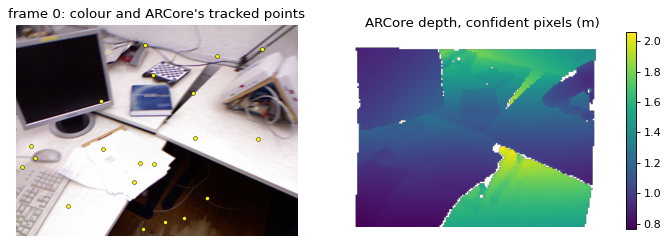

In [2]:
frames = list(session.frames(RECORDING))
with_depth = [f for f in frames if f.depth is not None]
anchors = [f.anchor_created[0] for f in frames if f.anchor_created is not None]
print(f"{len(frames)} frames, {frames[0].image.shape[1]} x {frames[0].image.shape[0]} pixels")
print(f"{len(with_depth)} carry ARCore depth ({with_depth[0].depth.depth_m.shape[1]} x {with_depth[0].depth.depth_m.shape[0]}), "
      f"{len(anchors)} start an anchor: {anchors}")

first = with_depth[0]
fig, (a, b) = plt.subplots(1, 2, figsize=(10, 3.6))
a.imshow(first.image)
a.scatter(*first.points_pixel.T, s=12, c="yellow", edgecolors="black", linewidths=0.4)
a.set_title(f"frame {first.seq}: colour and ARCore's tracked points")
im = b.imshow(np.where(first.depth.confidence >= 128, first.depth.depth_m, np.nan), cmap="viridis")
b.set_title("ARCore depth, confident pixels (m)")
fig.colorbar(im, ax=b, fraction=0.035)
for ax in (a, b):
    ax.axis("off")
plt.show()

## 2. The room build in one call

`build_room(folder, model, settings)` is the offline orchestrator, exactly what
`python -m apps.cli room` runs. It fuses every frame with fresh ARCore depth, then cleans and
measures the room once. The model is loaded once and passed in. The plots look down on the
room from above its dominant plane.

In [3]:
t0 = time.perf_counter()
model = depth.load_model(DEPTH_MODEL)
print(f"depth model loaded in {time.perf_counter() - t0:.1f} s")

t0 = time.perf_counter()
room = build_room(RECORDING, model, room_settings)
print(f"room built in {time.perf_counter() - t0:.1f} s")
summary = room.summary
print("frames:", summary["frames"])
print("clean-up:", {k: v for k, v in summary["clean_up"].items() if k != "clean_s"})
print("map:", {k: round(v, 3) for k, v in summary["map"].items() if k != "plane_normal"})

depth model loaded in 5.7 s


room built in 3.6 s
frames: {'fused': 7, 'turns_0': 1, 'turns_3': 6}
clean-up: {'raw_points': 55872, 'vote_removed': 232, 'pieces_removed': 3678, 'piece_cell_m': 0.02, 'pieces_kept_at_most': 50, 'piece_min_points': 5000}
map: {'observed_area_m2': 7.375, 'plane_area_m2': 3.15, 'length_m': 4.45, 'width_m': 3.15, 'highest_m': 0.526}


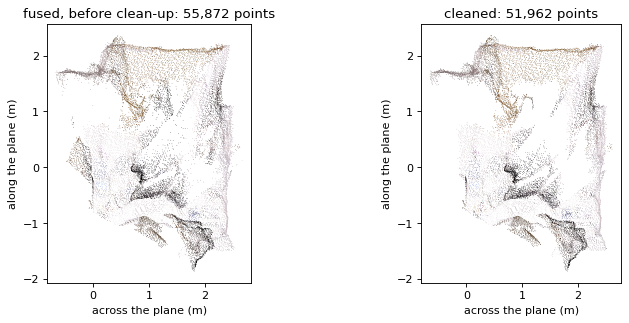

In [4]:
# View from above the dominant plane: two axes at right angles to its normal. This stand-in
# recording keeps TUM's world, where z is up; ARCore recordings have y up. The plane works for both.
normal = np.array(summary["map"]["plane_normal"])
across = np.cross(normal, [1.0, 0, 0] if abs(normal[0]) < 0.9 else [0, 1.0, 0])
across /= np.linalg.norm(across)
along = np.cross(normal, across)


def top_down(ax, points, colour, title, size=0.3):
    # Fused colours can sit just outside 0-1; the PLY writer clamps them the same way.
    colour = np.clip(colour, 0, 1) if isinstance(colour, np.ndarray) else colour
    ax.scatter(points @ across, points @ along, s=size, c=colour, linewidths=0)
    ax.set_aspect("equal")
    ax.set_xlabel("across the plane (m)")
    ax.set_ylabel("along the plane (m)")
    ax.set_title(title)

fig, (a, b) = plt.subplots(1, 2, figsize=(11, 4.2))
top_down(a, room.raw[::3], room.raw_colours[::3], f"fused, before clean-up: {len(room.raw):,} points")
top_down(b, room.surface[::3], room.raw_colours[room.cleaned.kept][::3], f"cleaned: {len(room.surface):,} points")
plt.show()

### What `build_room` wraps

The room build is one loop over frames and three calls at the end. Each line below is one stage
function from `sitescan/`; the orchestrator only decides which frames to use and in what order:

| Step | Call | Setting |
|---|---|---|
| Keep anchor events | `Fragments.set_anchor(id, world_from_anchor)` | |
| Skip stale or missing depth | `fresh_depth(frame)` | ARCore depth under 0.1 s older than the image |
| Predict depth, image upright | `depth.predict(model, colour, pose)` | |
| Fit the scale grid | `scale.depth_targets(...)`, `scale.fit_grid(...)` | 8 Ã— 6 cells, 50 pixels at least |
| Fuse | `Fragments.integrate(depth, colour, intrinsics, pose, keyframe)` | `far_m`, `voxel_m` |
| Clean | `vote_views(...)`, `cleanup.clean_room(points, views)` | 50 pieces of 5,000 points at least |
| Measure | `mapping.measure_site(surface, cameras)` | 5 cm cells |

The next sections run these by hand, one at a time.

## 3a. Choose the frames

The room build uses a frame only if it has a pose, an anchor before it, and ARCore depth measured
close enough in time to the image. Depth from a different moment belongs to a different view.

In [5]:
wire = list(session.read_wire_session(RECORDING))
keyframe, rows = None, []
for frame in wire:
    if frame.anchor_created is not None:
        keyframe = frame.anchor_created[0]
    if frame.depth is None:
        reason = "no ARCore depth"
    elif frame.pose is None or keyframe is None:
        reason = "no pose or anchor yet"
    elif not fresh_depth(frame):
        reason = "stale depth"
    else:
        reason = "fuse"
    rows.append((frame.seq, reason))
print(" ".join(f"{seq}:{reason}" for seq, reason in rows if reason != "no ARCore depth"))
print(sum(reason == "fuse" for _, reason in rows), "frames to fuse")

0:fuse 3:fuse 6:fuse 9:fuse 12:fuse 15:fuse 18:fuse
7 frames to fuse


## 3b. Depth: right shape, wrong scale

`depth.predict` turns the image upright first, because the model was trained on upright photos,
then turns the depth back so it lines up with the recorded pixels. The number of clockwise
quarter turns comes from the pose: the one that brings image-down closest to world-down.

frame 3: 3 quarter turn(s) to upright; learned depth median 1.54 m


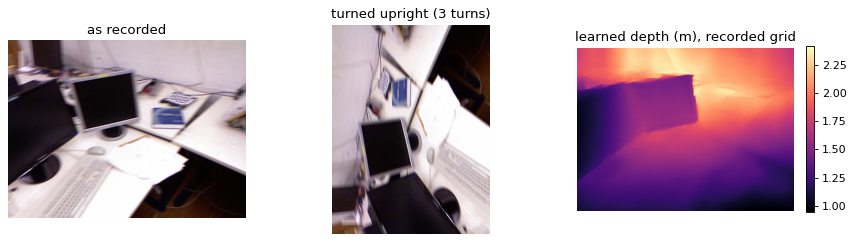

In [6]:
frame = next(f for f in wire if f.seq == 3)
pose = wire_v1.world_from_camera_cv(frame.pose)
colour = np.asarray(Image.open(io.BytesIO(frame.image_jpeg)).convert("RGB"))
turns = quarter_turns(pose)
learned, valid = depth.predict(model, colour, pose)
print(f"frame {frame.seq}: {turns} quarter turn(s) to upright; learned depth median {np.median(learned[valid]):.2f} m")

fig, axes = plt.subplots(1, 3, figsize=(13, 3.4))
axes[0].imshow(colour); axes[0].set_title("as recorded")
axes[1].imshow(upright(colour, turns)); axes[1].set_title(f"turned upright ({turns} turns)")
im = axes[2].imshow(np.where(valid, learned, np.nan), cmap="magma"); axes[2].set_title("learned depth (m), recorded grid")
fig.colorbar(im, ax=axes[2], fraction=0.035)
for ax in axes:
    ax.axis("off")
plt.show()

## 3c. Scale: learned depth to metres

ARCore's confident depth pixels are mapped into the colour image (`scale.depth_targets`). The scale
is the median ratio of ARCore depth to learned depth. `fit_one` gives one number for the frame;
`fit_grid` fits one per cell of an 8 Ã— 6 grid and blends between cells, which the room uses.

14541 ARCore targets; one scale 0.807; grid scale from 0.725 to 1.766


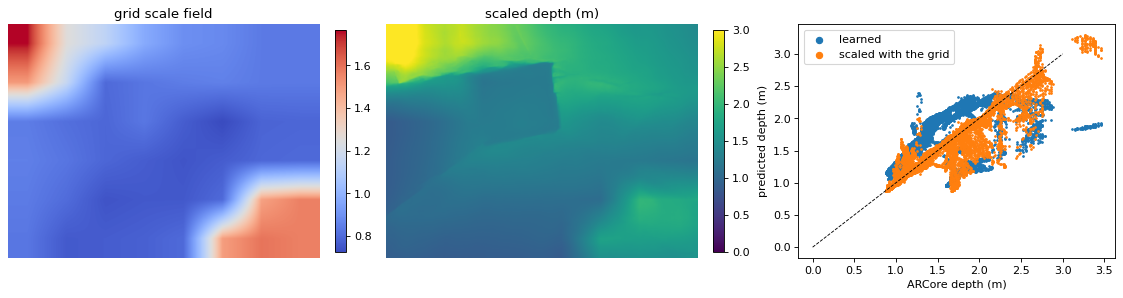

In [7]:
uv, target = scale.depth_targets(session.arcore_depth(frame.depth), session.camera(frame))
one = scale.fit_one(learned, valid, uv, target)
grid = scale.fit_grid(learned, valid, uv, target)
metric = learned * grid
print(f"{len(uv)} ARCore targets; one scale {one:.3f}; grid scale from {grid.min():.3f} to {grid.max():.3f}")

rows, cols = uv[:, 1].astype(int), uv[:, 0].astype(int)
fig, axes = plt.subplots(1, 3, figsize=(14, 3.6), layout="constrained")
im = axes[0].imshow(grid, cmap="coolwarm"); axes[0].set_title("grid scale field"); fig.colorbar(im, ax=axes[0], fraction=0.035)
im = axes[1].imshow(np.where(valid, metric, np.nan), cmap="viridis", vmin=0, vmax=3); axes[1].set_title("scaled depth (m)")
fig.colorbar(im, ax=axes[1], fraction=0.035)
axes[2].scatter(target, learned[rows, cols], s=2, label="learned")
axes[2].scatter(target, metric[rows, cols], s=2, label="scaled with the grid")
axes[2].plot([0, 3], [0, 3], "k--", lw=0.8)
axes[2].set_xlabel("ARCore depth (m)"); axes[2].set_ylabel("predicted depth (m)"); axes[2].legend(markerscale=4)
for ax in axes[:2]:
    ax.axis("off")
plt.show()

## 3d. Fusion, every frame

Now the whole loop by hand. Scaled depth up to `far_m` goes into the fragment of the frame's
keyframe; each fragment is stored relative to its anchor, so when ARCore corrects an anchor the
surface fused from it moves without being fused again. Depth up to 8 m is kept as see-through
evidence for the clean-up vote.

7 frames fused into 1 fragment(s): 55,872 points


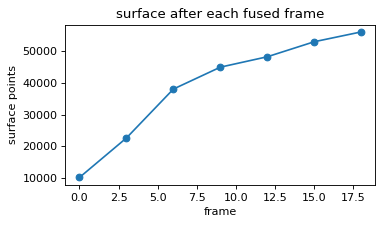

In [8]:
fragments = Fragments(voxel_m=room_settings.voxel_m)
placed, cameras, growth = [], [], []
keyframe = None
for frame in wire:
    if frame.anchor_created is not None:
        keyframe = frame.anchor_created[0]
        fragments.set_anchor(keyframe, wire_v1.world_from_camera(frame.anchor_created[1]))
    for anchor_id, anchor_pose in frame.anchor_updates.items():
        fragments.set_anchor(anchor_id, wire_v1.world_from_camera(anchor_pose))
    if frame.depth is None or frame.pose is None or keyframe is None or not fresh_depth(frame):
        continue
    pose = wire_v1.world_from_camera_cv(frame.pose)
    colour = np.asarray(Image.open(io.BytesIO(frame.image_jpeg)).convert("RGB"))
    learned, valid = depth.predict(model, colour, pose)
    uv, target = scale.depth_targets(session.arcore_depth(frame.depth), session.camera(frame))
    grid = scale.fit_grid(learned, valid, uv, target)
    if grid is None:
        continue
    metric = learned * grid
    fragments.integrate(np.where(valid & (metric < room_settings.far_m), metric, 0.0), colour,
                        frame.intrinsics, pose, keyframe)
    evidence = np.where(valid & (metric < VOTE_FAR_M), metric, 0.0).astype(np.float32)
    placed.append((pose, frame.intrinsics, keyframe, fragments.placing_anchor(keyframe).copy(), evidence))
    cameras.append(pose[:3, 3])
    growth.append((frame.seq, len(fragments.surface())))

raw, raw_colours = fragments.surface(), fragments.colours()
print(f"{len(placed)} frames fused into {len(fragments.frames_per_fragment())} fragment(s): {len(raw):,} points")
plt.figure(figsize=(5, 2.6))
plt.plot(*zip(*growth), "o-")
plt.xlabel("frame"); plt.ylabel("surface points"); plt.title("surface after each fused frame")
plt.show()

## 3e. Clean-up

Two filters, in order. The **visibility vote** drops a point when the views that see through it
outweigh the views that measure it there (each view weighted by 1 / depthÂ²). The **largest pieces**
filter joins filled 2 cm cells that touch and keeps the 50 largest pieces of at least 5,000
points; floating debris is in small pieces. Each camera is first moved by its anchor's
correction since it was fused, as its surface was.

vote removed 232; pieces removed 3,678; kept 51,962


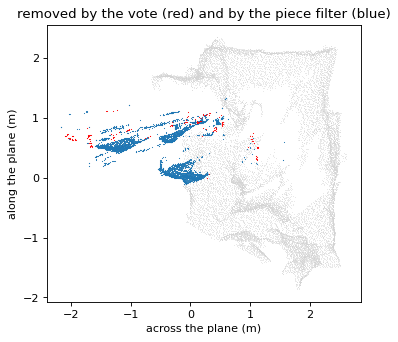

In [9]:
views = vote_views(fragments, placed)
cleaned = cleanup.clean_room(raw, views, cell=room_settings.piece_cell_m or room_settings.voxel_m)
by_vote = ~cleaned.voted
by_pieces = cleaned.voted & ~cleaned.kept
print(f"vote removed {by_vote.sum():,}; pieces removed {by_pieces.sum():,}; kept {cleaned.kept.sum():,}")

fig, ax = plt.subplots(figsize=(6, 4.5))
top_down(ax, raw[cleaned.kept][::3], "lightgrey", "removed by the vote (red) and by the piece filter (blue)")
ax.scatter(raw[by_vote, 0], raw[by_vote, 2], s=1, c="red", linewidths=0)
ax.scatter(raw[by_pieces, 0], raw[by_pieces, 2], s=1, c="tab:blue", linewidths=0)
plt.show()

## 3f. Mapping

`mapping.measure_site` thins the surface to half a map cell, finds the dominant plane with a
seeded RANSAC, lays a 5 cm grid on that plane and reads off the observed area, length, width and
the highest point above the plane. Unwrapped, it is `fit_dominant_plane` then `footprint`.

{'observed_area_m2': 7.375, 'plane_area_m2': 3.15, 'length_m': 4.45, 'width_m': 3.15, 'highest_m': 0.526}
plane normal [-0.01  -0.023  1.   ], 20% of points on it


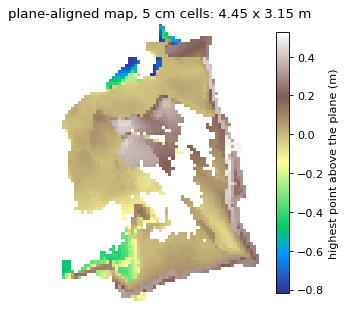

In [10]:
import open3d as o3d

surface = raw[cleaned.kept]
site = mapping.measure_site(surface, cameras)
thinned = np.asarray(o3d.geometry.PointCloud(o3d.utility.Vector3dVector(surface)).voxel_down_sample(0.025).points)
plane = mapping.fit_dominant_plane(thinned)
grid_map = mapping.footprint(thinned, plane, np.mean(cameras, 0) - plane.point)
print({k: round(v, 3) for k, v in site.items() if k != "plane_normal"})
print(f"plane normal {np.round(plane.normal, 3)}, {plane.inlier_fraction:.0%} of points on it")

plt.figure(figsize=(6, 4.5))
heights = np.where(grid_map.observed, grid_map.max_height_m, np.nan)
plt.imshow(heights, cmap="terrain", origin="lower")
plt.colorbar(label="highest point above the plane (m)", fraction=0.035)
plt.title(f"plane-aligned map, {grid_map.cell_size_m * 100:.0f} cm cells: {site['length_m']:.2f} x {site['width_m']:.2f} m")
plt.axis("off")
plt.show()

## 3g. Same answer?

The hand-run steps must give exactly what `build_room` gave.

In [11]:
assert len(raw) == summary["clean_up"]["raw_points"]
assert by_vote.sum() == summary["clean_up"]["vote_removed"] and by_pieces.sum() == summary["clean_up"]["pieces_removed"]
assert len(surface) == summary["surface_points"]
assert site == summary["map"]
print(f"unwrapped steps match build_room: {len(surface):,} points, {site['length_m']:.2f} x {site['width_m']:.2f} m")

unwrapped steps match build_room: 51,962 points, 4.45 x 3.15 m


## 4. The live processor

`LiveProcessor` is the live orchestrator. `add()` records each frame as it arrives; `update()`
works on the newest posed frame and returns one record. Here every frame is added and updated
in turn, without threads, as the golden test does. In a real run `run_live` calls `update()` as
often as it can while frames arrive, so most frames are never processed.

20 updates; scale sources: {'arcore_depth': 7, 'tracked_points': 13}
last update: {'frame_seq': 19, 'scale': 0.6860369180733183, 'scale_source': 'tracked_points', 'surface_points': 73191}


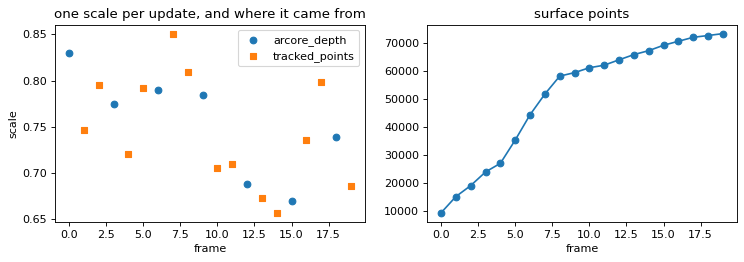

In [12]:
processor = LiveProcessor(model, None, live_settings)
records = []
for frame in wire:
    processor.add(frame, RECORDING / "frames" / f"{frame.seq:06d}.jpg")
    record = processor.update()
    if record is not None:
        records.append(record)
print(f"{len(records)} updates; scale sources:", {s: sum(r['scale_source'] == s for r in records) for s in {r['scale_source'] for r in records}})
print("last update:", {k: records[-1][k] for k in ("frame_seq", "scale", "scale_source", "surface_points")})

fig, (a, b) = plt.subplots(1, 2, figsize=(11, 3.2))
seqs = [r["frame_seq"] for r in records]
for source, marker in (("arcore_depth", "o"), ("tracked_points", "s"), ("previous", "x")):
    picked = [(r["frame_seq"], r["scale"]) for r in records if r["scale_source"] == source]
    if picked:
        a.scatter(*zip(*picked), marker=marker, label=source)
a.set_xlabel("frame"); a.set_ylabel("scale"); a.legend(); a.set_title("one scale per update, and where it came from")
b.plot(seqs, [r["surface_points"] for r in records], "o-"); b.set_xlabel("frame"); b.set_title("surface points")
plt.show()

### What one live update wraps

An update predicts depth on the image as recorded (live does not turn it upright yet), fits one
scale with a fallback chain (ARCore depth, else ARCore's tracked points, else the previous
scale), fuses depth in 0.1â€“4 m, and measures the whole surface. Frame 1 has no ARCore depth, so
its scale comes from tracked points:

In [13]:
frame = next(f for f in wire if f.seq == 1)
colour = np.asarray(Image.open(RECORDING / "frames" / f"{frame.seq:06d}.jpg").convert("RGB"))
learned, valid = model(colour)
fitted, source = frame_scale(learned, valid, frame, previous=records[0]["scale"])
logged = next(r for r in records if r["frame_seq"] == 1)
print(f"by hand: {fitted:.4f} from {source}; the processor logged {logged['scale']:.4f} from {logged['scale_source']}")
assert (fitted, source) == (logged["scale"], logged["scale_source"])

by hand: 0.7467 from tracked_points; the processor logged 0.7467 from tracked_points


## 5. Objects (optional, experimental)

`objects.load_detector` loads YOLO26x once and checks its hash. Each box is placed in 3D at the
median of the scaled depth inside it, and `Objects.update` matches it to objects of the same class
within 0.35 m. Counting overcounts today (see `sitescan/objects/README.md`). This section needs the
`objects` extra and `models/yolo26x.pt`, and skips itself without them.

WARNING 'half' is deprecated and will be removed in the future. Use 'quantize' instead.


counts: {'tv': 2, 'keyboard': 1, 'mouse': 1, 'cup': 1}


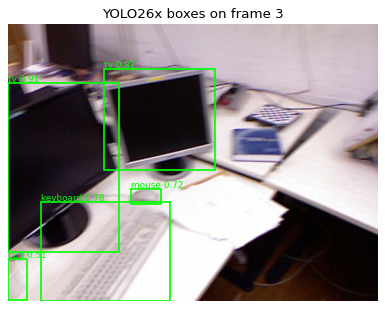

In [14]:
from sitescan.objects import Objects, load_detector

try:
    detector = load_detector(DETECTOR_MODEL)
except (FileNotFoundError, ImportError, ValueError) as reason:
    detector = None
    print("objects skipped:", reason)

if detector is not None:
    counted = Objects()
    frame = next(f for f in wire if f.seq == 3)
    pose = wire_v1.world_from_camera_cv(frame.pose)
    colour = np.asarray(Image.open(io.BytesIO(frame.image_jpeg)).convert("RGB"))
    learned, valid = depth.predict(model, colour, pose)
    uv, target = scale.depth_targets(session.arcore_depth(frame.depth), session.camera(frame))
    metric = learned * scale.fit_grid(learned, valid, uv, target)
    found = detector(colour)
    rows = counted.update(found, metric, valid, session.camera(frame), pose, 0, {0: np.eye(4)}, 1)
    print("counts:", counted.counts())
    fig, ax = plt.subplots(figsize=(6, 4.5))
    ax.imshow(colour)
    for detection, row in zip(found, rows):
        x1, y1, x2, y2 = detection.xyxy
        ax.add_patch(plt.Rectangle((x1, y1), x2 - x1, y2 - y1, fill=False, color="lime", lw=1.5))
        ax.text(x1, y1 - 3, f"{detection.label} {detection.confidence:.2f}", color="lime", fontsize=8)
    ax.axis("off"); ax.set_title("YOLO26x boxes on frame 3")
    plt.show()

## Where next

- Each stage's README (`sitescan/<stage>/README.md`) gives its inputs, steps, settings with their
  evidence, limits and tests.
- The root README's function index lists every public function with a link to its code.
- The root README's Future work section lists the next changes in order, starting with giving the
  live processor the room build's upright images, grid scale and fresh-depth rule.